/Users/evandaniels/Research/runs/conducting_y_walls/di_0.0: 51 outputs used, midplane y = 0.0000, probe at (-4.01, 6.01)
/Users/evandaniels/Research/runs/conducting_y_walls/di_0_cflem0.2: 51 outputs used, midplane y = 0.0000, probe at (-4.01, 6.01)
/Users/evandaniels/Research/runs/conducting_y_walls/di_0.5_res0.5: 51 outputs used, midplane y = -0.0000, probe at (-3.99, 6.02)
/Users/evandaniels/Research/runs/conducting_y_walls/di_0.5: 51 outputs used, midplane y = 0.0000, probe at (-4.01, 6.01)
/Users/evandaniels/Research/runs/conducting_y_walls/di_0.5_cflem0.2: 51 outputs used, midplane y = 0.0000, probe at (-4.01, 6.01)
saved /Users/evandaniels/Research/runs/di_comparison.png


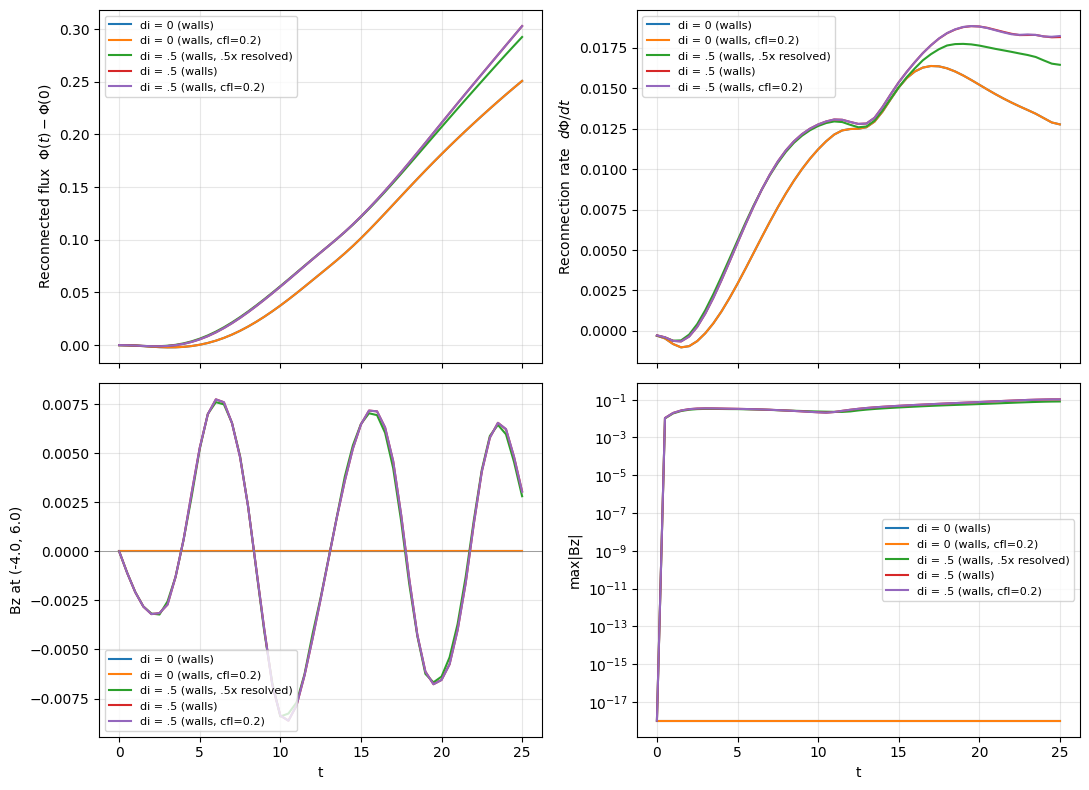

In [64]:
"""
compare_di_runs.py -- reconnected flux and Bz time series across several di runs

For each run directory it computes, at every output time:
  1. Reconnected flux  Phi(t): flux function along the midplane y ~ 0,
       psi(x) = integral of By dx,   Phi = max(psi) - min(psi)
     (the extrema of psi along the midplane sit at the X- and O-points,
      so this does not depend on knowing where they are)
     reported as Phi(t) - Phi(0), plus the rate dPhi/dt
  2. Bz at a fixed probe point (default (x, y) = (-4, 6))
  3. max|Bz| over the whole domain

File mapping (writeout.cc): b1 = Bx, b2 = By (in-plane), b3 = Bz (out-of-plane)
"""

import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------------
# Settings -- edit these
# ----------------------------------------------------------------------------
BASE = os.path.expanduser('~/Research/runs')

RUNS = {                     # label : folder under BASE
    # 'di = 0 (periodic)':    'periodic_y_boundary/di_0.0',
    'di = 0 (walls)':    'conducting_y_walls/di_0.0',
    # 'di = .1 (walls)':    'conducting_y_walls/di_0.1',
    # 'di = .1 (walls, .5x resolved)':    'conducting_y_walls/di_0.1_res0.5',
    'di = 0 (walls, cfl=0.2)':    'conducting_y_walls/di_0_cflem0.2',
    'di = .5 (walls, .5x resolved)':    'conducting_y_walls/di_0.5_res0.5',
    'di = .5 (walls)':    'conducting_y_walls/di_0.5',
    'di = .5 (walls, cfl=0.2)':    'conducting_y_walls/di_0.5_cflem0.2'
    # 'di = 0.1':  'di_0.1',
    # 'di = 0.25': 'di_0.25',
    # 'di = 0.5':  'di_0.5',
}

P      = 10          # MPI ranks
DT_OUT = 0.5         # output interval
PROBE  = (-4.0, 6.0) # (x, y) for the Bz time series


# ----------------------------------------------------------------------------
def load_field(run_dir, name, n):
    """Stack per-rank files into one [x, y] array."""
    return np.vstack([np.loadtxt(f'{run_dir}/{name}_files/{name}_p{p:03d}_{n:03d}')
                      for p in range(P)])


def analyze_run(run_dir):
    y = np.loadtxt(f'{run_dir}/mesh_files/y')
    x = np.concatenate([np.loadtxt(f'{run_dir}/mesh_files/x_p{p:03d}') for p in range(P)])

    N = len(glob.glob(f'{run_dir}/b2_files/b2_p000_*'))

    k_mid = np.argmin(np.abs(y))                 # row closest to y = 0
    j_pr  = np.argmin(np.abs(x - PROBE[0]))
    k_pr  = np.argmin(np.abs(y - PROBE[1]))

    t, phi, bz_probe, bz_max = [], [], [], []
    for n in range(N):
        By = load_field(run_dir, 'b2', n)
        Bz = load_field(run_dir, 'b3', n)

        by_mid = By[:, k_mid]
        # cumulative trapezoid integral of By along x
        psi = np.concatenate([[0.0], np.cumsum(0.5*(by_mid[1:] + by_mid[:-1])*np.diff(x))])

        t.append(n*DT_OUT)
        phi.append(psi.max() - psi.min())
        bz_probe.append(Bz[j_pr, k_pr])
        bz_max.append(np.abs(Bz).max())

    # keep only outputs up to t_final (drops the repeated final writeout)
    T_FINAL = 25.0
    keep = [i for i, ti in enumerate(t) if ti <= T_FINAL + 1e-9]
    t        = [t[i] for i in keep]
    phi      = [phi[i] for i in keep]
    bz_probe = [bz_probe[i] for i in keep]
    bz_max   = [bz_max[i] for i in keep]

    t    = np.array(t)
    phi  = np.array(phi) - phi[0]
    rate = np.gradient(phi, t)

    print(f'{run_dir}: {len(t)} outputs used, midplane y = {y[k_mid]:.4f}, '
          f'probe at ({x[j_pr]:.2f}, {y[k_pr]:.2f})')
    return dict(t=t, phi=phi, rate=rate,
                bz_probe=np.array(bz_probe), bz_max=np.array(bz_max))


# ----------------------------------------------------------------------------
results = {}
for label, folder in RUNS.items():
    run_dir = os.path.join(BASE, folder)
    if not os.path.isdir(run_dir):
        print(f'skipping {label}: {run_dir} not found')
        continue
    results[label] = analyze_run(run_dir)

fig, axs = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
(ax_phi, ax_rate), (ax_probe, ax_bzmax) = axs

for label, r in results.items():
    ax_phi.plot(r['t'], r['phi'], label=label)
    ax_rate.plot(r['t'], r['rate'], label=label)
    ax_probe.plot(r['t'], r['bz_probe'], label=label)
    ax_bzmax.semilogy(r['t'], np.maximum(r['bz_max'], 1e-18), label=label)

ax_phi.set_ylabel(r'Reconnected flux  $\Phi(t)-\Phi(0)$')
ax_rate.set_ylabel(r'Reconnection rate  $d\Phi/dt$')
ax_probe.set_ylabel(f'Bz at ({PROBE[0]}, {PROBE[1]})')
ax_bzmax.set_ylabel('max|Bz|')
ax_probe.axhline(0, color='gray', lw=0.5)
for ax in axs.flat:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
for ax in axs[1]:
    ax.set_xlabel('t')

fig.tight_layout()
out = os.path.join(BASE, 'di_comparison.png')
fig.savefig(out, dpi=150)
print(f'saved {out}')
plt.show()

# Save the numbers too, one CSV per run
for label, r in results.items():
    fname = os.path.join(BASE, f"timeseries_{label.replace(' ', '').replace('=', '_')}.csv")
    np.savetxt(fname, np.column_stack([r['t'], r['phi'], r['rate'], r['bz_probe'], r['bz_max']]),
               delimiter=',', header='t,phi,rate,bz_probe,bz_max', comments='')

# ----------------------------------------------------------------------------
# Resolution comparison at a single di (nothing saved, plot only)
# ----------------------------------------------------------------------------
RES_RUNS = {                     # label : folder under BASE   (all the SAME di)
    'res x0.5': 'di_0.1_res0.5',
    'res x1':   'di_0.1',
    # 'res x2':   'di_0.1_res2.0',
}
DI_LABEL = 'di = 0.1'            # used only for the figure title

res_results = {}
for label, folder in RES_RUNS.items():
    run_dir = os.path.join(BASE, folder)
    if not os.path.isdir(run_dir):
        print(f'skipping {label}: {run_dir} not found')
        continue
    res_results[label] = analyze_run(run_dir)

fig, axs = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
(ax_phi, ax_rate), (ax_probe, ax_bzmax) = axs

for label, r in res_results.items():
    ax_phi.plot(r['t'], r['phi'], label=label)
    ax_rate.plot(r['t'], r['rate'], label=label)
    ax_probe.plot(r['t'], r['bz_probe'], label=label)
    ax_bzmax.semilogy(r['t'], np.maximum(r['bz_max'], 1e-18), label=label)

ax_phi.set_ylabel(r'Reconnected flux  $\Phi(t)-\Phi(0)$')
ax_rate.set_ylabel(r'Reconnection rate  $d\Phi/dt$')
ax_probe.set_ylabel(f'Bz at ({PROBE[0]}, {PROBE[1]})')
ax_bzmax.set_ylabel('max|Bz|')
ax_probe.axhline(0, color='gray', lw=0.5)
for ax in axs.flat:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
for ax in axs[1]:
    ax.set_xlabel('t')
fig.suptitle(f'{DI_LABEL}: resolution comparison')
fig.tight_layout()
plt.show()

# Quick numbers to compare across resolutions
print(f"{'':>10} {'peak rate':>10} {'t_peak':>7} {'final flux':>11} {'final max|Bz|':>14}")
for label, r in res_results.items():
    i = np.argmax(r['rate'])
    print(f"{label:>10} {r['rate'][i]:>10.5f} {r['t'][i]:>7.1f} {r['phi'][-1]:>11.4f} {r['bz_max'][-1]:>14.3e}")
for label, folder in RES_RUNS.items():
    d = os.path.join(BASE, folder)
    y = np.loadtxt(f'{d}/mesh_files/y')
    nx = sum(len(np.loadtxt(f'{d}/mesh_files/x_p{p:03d}')) for p in range(P))
    print(label, nx, 'x', len(y))

/Users/evandaniels/Research/runs/conducting_y_walls/di_0_cflem0.2: 51 outputs used, midplane y = 0.0000, probe at (-4.01, 6.01)
di = 0 (conducting walls, cfl=.2): peak |Jz| = 2.223 at x = -0.01, y = 0.00


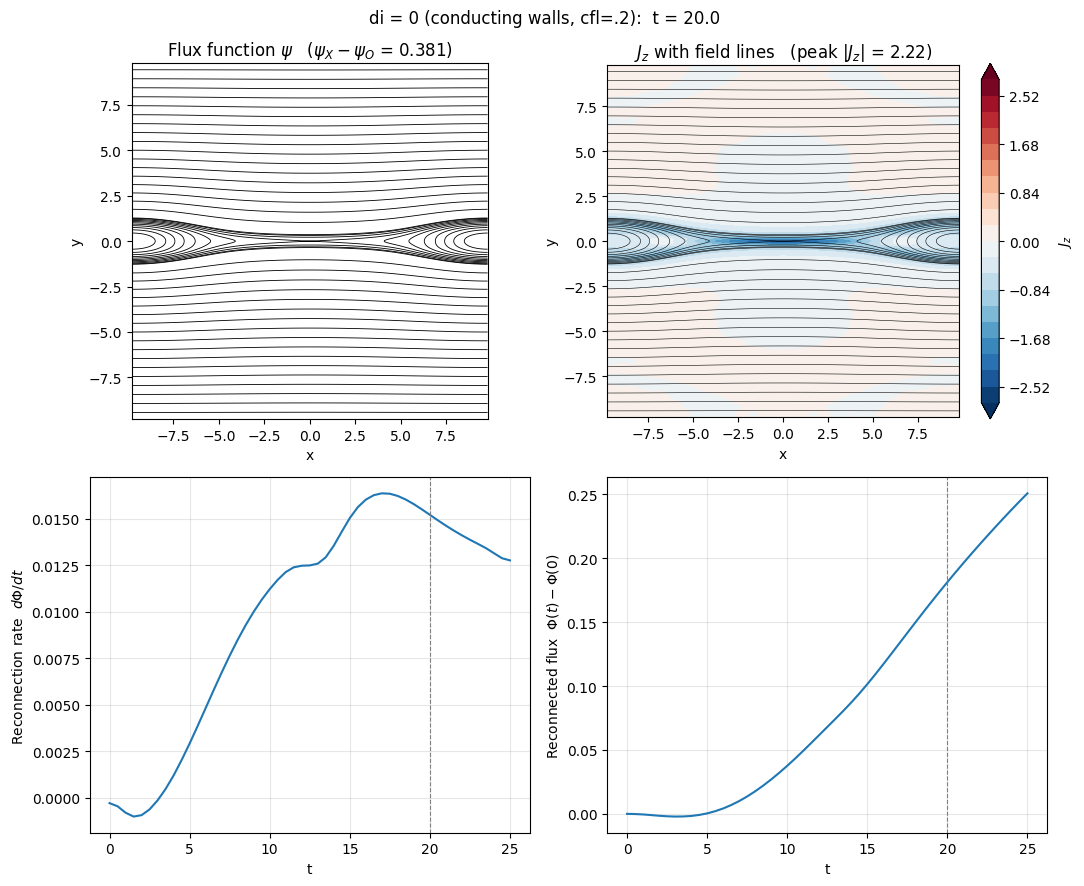

di = 0 (periodic y): length FWHM = 8.923, thickness FWHM = 0.5508, aspect d/L = 0.0617
di = 0 (walls, cfl = .4): length FWHM = 8.943, thickness FWHM = 0.5547, aspect d/L = 0.0620
di = 0 (walls, cfl = .2): length FWHM = 8.943, thickness FWHM = 0.5547, aspect d/L = 0.0620
di = .5 (walls, .5x resolved): length FWHM = 6.924, thickness FWHM = 0.5046, aspect d/L = 0.0729
di = .5 (walls, cfl = .4): length FWHM = 6.544, thickness FWHM = 0.4333, aspect d/L = 0.0662
di = .5 (walls, cfl = .2): length FWHM = 6.544, thickness FWHM = 0.4324, aspect d/L = 0.0661


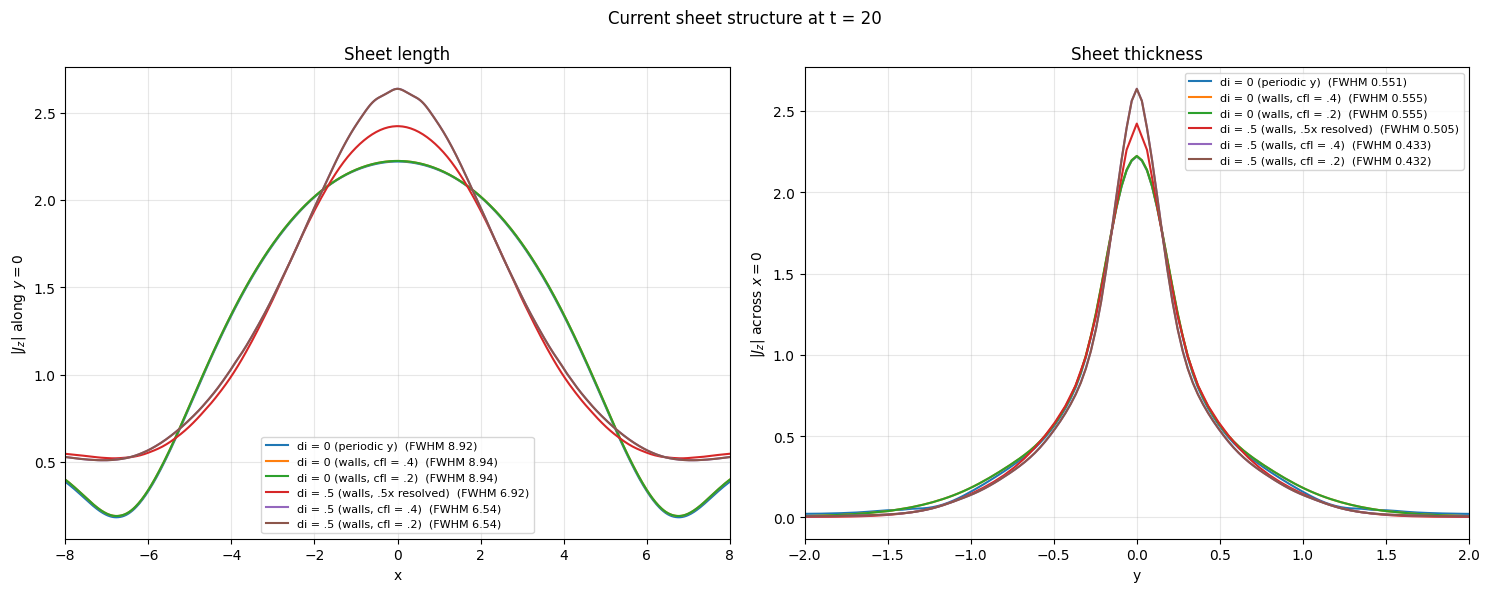

In [67]:
# ----------------------------------------------------------------------------
# Dr. Yoon's diagnostics for ONE run: psi, Jz, reconnection rate, flux
# ----------------------------------------------------------------------------
def flux_function(Bx, By, x, y):
    """psi with Bx = dpsi/dy, By = -dpsi/dx (contours of psi = in-plane field lines).
    Arrays indexed [x, y]. Defined up to a constant."""
    psi_edge = np.concatenate([[0.0], np.cumsum(0.5*(Bx[0, 1:] + Bx[0, :-1])*np.diff(y))])
    int_by = np.vstack([np.zeros((1, By.shape[1])),
                        np.cumsum(0.5*(By[1:, :] + By[:-1, :])*np.diff(x)[:, None], axis=0)])
    return psi_edge[None, :] - int_by


def psi_levels(psi, k_mid, n_fine=8, coarse=0.5):
    """Fine contour spacing across the island flux, coarse far from the sheet."""
    mid = psi[:, k_mid]
    lo, hi = mid.min(), mid.max()
    d = (hi - lo)/n_fine if hi > lo else 0.01
    fine = np.arange(lo - 2*d, hi + 2.5*d, d)
    far = np.arange(np.floor(psi.min()/coarse)*coarse, psi.max() + coarse, coarse)
    far = far[(far < fine[0]) | (far > fine[-1])]
    return np.unique(np.round(np.concatenate([fine, far]), 10))


def load_snapshot(folder, t_snap):
    """Mesh, psi (0 at the O-point), Jz and the output index for one run at one time."""
    run_dir = os.path.join(BASE, folder)
    y = np.loadtxt(f'{run_dir}/mesh_files/y')
    x = np.concatenate([np.loadtxt(f'{run_dir}/mesh_files/x_p{p:03d}') for p in range(P)])
    k_mid = np.argmin(np.abs(y))
    n = int(round(t_snap/DT_OUT))
    Bx, By = load_field(run_dir, 'b1', n), load_field(run_dir, 'b2', n)
    psi = flux_function(Bx, By, x, y)
    psi = psi - psi[:, k_mid].min()                     # psi = 0 at the O-point
    jz = np.gradient(By, x, axis=0) - np.gradient(Bx, y, axis=1)
    return run_dir, x, y, k_mid, n, psi, jz


def yoon_panel(folder, t_snap, label=None, jlim=None, zoom=(-5, 5, -2, 2)):
    """jlim: shared Jz color limit (use the same value for runs you compare).
    zoom: (xmin, xmax, ymin, ymax) for the Jz panel, or None for the full domain."""
    run_dir, x, y, k_mid, n, psi, jz = load_snapshot(folder, t_snap)
    flux_now = psi[:, k_mid].max()                      # psi_X - psi_O
    levels = psi_levels(psi, k_mid)
    r = analyze_run(run_dir)                            # time series (rate, flux)

    # peak current of the physical sheet (rows near the periodic y boundary excluded)
    interior = np.abs(y) < 0.8*np.abs(y).max()
    jz_int = jz[:, interior]
    jj, kk = np.unravel_index(np.argmax(np.abs(jz_int)), jz_int.shape)
    jz_peak = np.abs(jz_int[jj, kk])
    print(f'{label or folder}: peak |Jz| = {jz_peak:.3f} at x = {x[jj]:.2f}, y = {y[interior][kk]:.2f}')
    if jlim is None:
        jlim = jz_peak

    fig, axs = plt.subplots(2, 2, figsize=(11, 9))
    (ax_psi, ax_jz), (ax_rate, ax_phi) = axs

    # flux function (full domain, true geometry)
    ax_psi.contour(x, y, psi.T, levels=levels, colors='black', linewidths=0.6)
    ax_psi.set_title(r'Flux function $\psi$' + f'   ($\\psi_X-\\psi_O$ = {flux_now:.3f})')
    ax_psi.set_aspect('equal')

    # out-of-plane current with field lines (shared color scale, saturates beyond jlim)
    cf = ax_jz.contourf(x, y, jz.T, levels=np.linspace(-jlim, jlim, 21),
                        cmap='RdBu_r', extend='both')
    fig.colorbar(cf, ax=ax_jz, label=r'$J_z$')
    ax_jz.contour(x, y, psi.T, levels=levels, colors='black', linewidths=0.4)
    ax_jz.set_title(r'$J_z$ with field lines' + f'   (peak $|J_z|$ = {jz_peak:.2f})')
    if zoom is not None:
        ax_jz.set_xlim(zoom[0], zoom[1]); ax_jz.set_ylim(zoom[2], zoom[3])
        ax_jz.set_aspect('auto')                        # fill the panel
    else:
        ax_jz.set_aspect('equal')

    for ax in (ax_psi, ax_jz):
        ax.set_xlabel('x'); ax.set_ylabel('y')

    # reconnection rate and flux vs time, snapshot time marked
    ax_rate.plot(r['t'], r['rate'])
    ax_rate.set_ylabel(r'Reconnection rate  $d\Phi/dt$')
    ax_phi.plot(r['t'], r['phi'])
    ax_phi.set_ylabel(r'Reconnected flux  $\Phi(t)-\Phi(0)$')
    for ax in (ax_rate, ax_phi):
        ax.axvline(n*DT_OUT, color='gray', ls='--', lw=0.8)
        ax.set_xlabel('t')
        ax.grid(alpha=0.3)

    fig.suptitle(f'{label or folder}:  t = {n*DT_OUT:.1f}')
    fig.tight_layout()
    plt.show()


# ----------------------------------------------------------------------------
# Current-sheet cuts: length (along y = 0) and thickness (across x = 0)
# ----------------------------------------------------------------------------
def fwhm(coord, prof):
    """Full width at half max of prof around its peak (interpolated crossings)."""
    i0 = np.argmax(prof); half = 0.5*prof[i0]
    l = i0
    while l > 0 and prof[l - 1] >= half: l -= 1
    rr = i0
    while rr < len(prof) - 1 and prof[rr + 1] >= half: rr += 1
    cl = np.interp(half, [prof[l - 1], prof[l]], [coord[l - 1], coord[l]]) if l > 0 else coord[l]
    cr = np.interp(half, [prof[rr + 1], prof[rr]], [coord[rr + 1], coord[rr]]) if rr < len(prof) - 1 else coord[rr]
    return cr - cl


def sheet_cuts(runs, t_snap, xlim=(-8, 8), ylim=(-2, 2)):
    """runs: dict label -> folder. Overlays |Jz| along y=0 and across x=0, prints FWHMs."""
    fig, (ax_len, ax_thk) = plt.subplots(1, 2, figsize=(15, 6))
    for label, folder in runs.items():
        _, x, y, k_mid, n, _, jz = load_snapshot(folder, t_snap)
        j0 = np.argmin(np.abs(x))
        along = np.abs(jz[:, k_mid])                    # along the sheet (length)
        across = np.abs(jz[j0, :])                      # across the sheet (thickness)
        inner = np.abs(y) < 0.8*np.abs(y).max()         # keep the boundary sheet out of the FWHM
        L, d = fwhm(x, along), fwhm(y[inner], across[inner])
        ax_len.plot(x, along, label=f'{label}  (FWHM {L:.2f})')
        ax_thk.plot(y, across, label=f'{label}  (FWHM {d:.3f})')
        print(f'{label}: length FWHM = {L:.3f}, thickness FWHM = {d:.4f}, aspect d/L = {d/L:.4f}')
    ax_len.set(xlim=xlim, xlabel='x', ylabel=r'$|J_z|$ along $y=0$', title='Sheet length')
    ax_thk.set(xlim=ylim, xlabel='y', ylabel=r'$|J_z|$ across $x=0$', title='Sheet thickness')
    for ax in (ax_len, ax_thk):
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.suptitle(f'Current sheet structure at t = {t_snap}')
    fig.tight_layout()
    plt.show()


# ---- usage ----
JLIM = 2.8                                              # same Jz color scale for both runs
# yoon_panel('conducting_y_walls/di_0.0', t_snap=20, label='di = 0.0', jlim=JLIM, zoom=None)
# yoon_panel('conducting_y_walls/di_0_cflem0.2', t_snap=20, label='di = 0 (conducting walls, cfl=.2)', jlim=JLIM, zoom=None)
# yoon_panel('periodic_y_boundary/di_0.0', t_snap=20, label='di = 0 (periodic y)', jlim=JLIM, zoom=None)
# yoon_panel('conducting_y_walls/di_0.1', t_snap=20, label='di = .1 (conducting walls)', jlim=JLIM, zoom=None)
# yoon_panel('conducting_y_walls/di_0.1_res0.5', t_snap=20, label='di = .1 (conducting walls, .5x resolved)', jlim=JLIM, zoom=None)
# yoon_panel('conducting_y_walls/di_0.5_res0.5', t_snap=20, label='di = .5 (conducting walls, .5x resolved)', jlim=JLIM, zoom=None)
# yoon_panel('conducting_y_walls/di_0.5', t_snap=20, label='di = .5 (conducting walls)', jlim=JLIM, zoom=None)
yoon_panel('conducting_y_walls/di_0_cflem0.2', t_snap=20, label='di = 0 (conducting walls, cfl=.2)', jlim=JLIM, zoom=None)
sheet_cuts({'di = 0 (periodic y)': 'periodic_y_boundary/di_0.0',
            'di = 0 (walls, cfl = .4)':      'conducting_y_walls/di_0.0',
            'di = 0 (walls, cfl = .2)': 'conducting_y_walls/di_0_cflem0.2',
            # 'di = .1 (walls)':      'conducting_y_walls/di_0.1',
            # 'di = .1 (walls, .5x resolved)': 'conducting_y_walls/di_0.1_res0.5',
            'di = .5 (walls, .5x resolved)': 'conducting_y_walls/di_0.5_res0.5',
            'di = .5 (walls, cfl = .4)': 'conducting_y_walls/di_0.5',
            'di = .5 (walls, cfl = .2)': 'conducting_y_walls/di_0.5_cflem0.2'}, t_snap=20)